# AulaSense: Análisis del diseño original

**Materia:** Ingeniería en Software  
**Proyecto:** AulaSense – Monitoreo Inteligente de Aulas  
**Actividad:** Análisis y mejora del diseño de software

## 1. Descripción del proyecto

AulaSense es una propuesta de sistema IoT que permite monitorear
la ocupación y las condiciones ambientales de las aulas de una
institución educativa.

El sistema utiliza sensores para obtener información sobre
temperatura, humedad, presencia de personas y calidad del aire.

Los datos se envían a un servidor, donde se procesan y almacenan
para posteriormente mostrarse en un dashboard mediante gráficas,
consultas y alertas.

## 2. Diseño original supuesto

Para analizar la organización del software, se considera
inicialmente una clase llamada SistemaAulaSense.

Esta clase concentra las funciones de recepción, validación,
procesamiento, almacenamiento, alertas, visualización y
administración.

Este diseño es una representación hipotética basada en los
requisitos del proyecto, ya que todavía no se cuenta con una
implementación original verificada.

## 3. Identificación de responsabilidades

En el diseño original supuesto, la clase `SistemaAulaSense`
se encarga de realizar diferentes funciones relacionadas
con el monitoreo de las aulas.

Las responsabilidades identificadas son:

| Responsabilidad | Métodos | Función |
|---|---|---|
| Recepción y validación | recibirLectura(), validarLectura() | Recibir los datos de los sensores y comprobar que sean válidos. |
| Procesamiento | estimarOcupacion(), detectarEvento() | Interpretar la ocupación del aula e identificar condiciones fuera de los parámetros establecidos. |
| Almacenamiento | guardarMedicion(), consultarHistorial() | Guardar las mediciones y recuperar registros anteriores. |
| Alertas | generarAlerta(), notificar() | Detectar situaciones que requieren atención y enviar notificaciones. |
| Visualización | mostrarDashboard(), generarReporte() | Mostrar los datos mediante gráficas y reportes. |
| Administración | gestionarUsuarios(), gestionarAulas() | Administrar usuarios, permisos y aulas registradas. |
| Dispositivos | registrarDispositivo(), consultarEstado() | Registrar sensores y consultar su estado de funcionamiento. |

### Problema inicial observado

La clase `SistemaAulaSense` concentra siete responsabilidades
diferentes dentro de un mismo componente.

Esto significa que cualquier modificación relacionada con
los

## 4. Diagrama del diseño original

El siguiente diagrama representa la estructura inicial
supuesta de AulaSense.

En este diseño, la clase SistemaAulaSense concentra
las responsabilidades principales del servidor.

El nodo IoT envía las lecturas, mientras que la clase
central se comunica con la base de datos y la interfaz
de usuario.

Las flechas representan comunicación o uso entre
componentes, no relaciones de herencia.

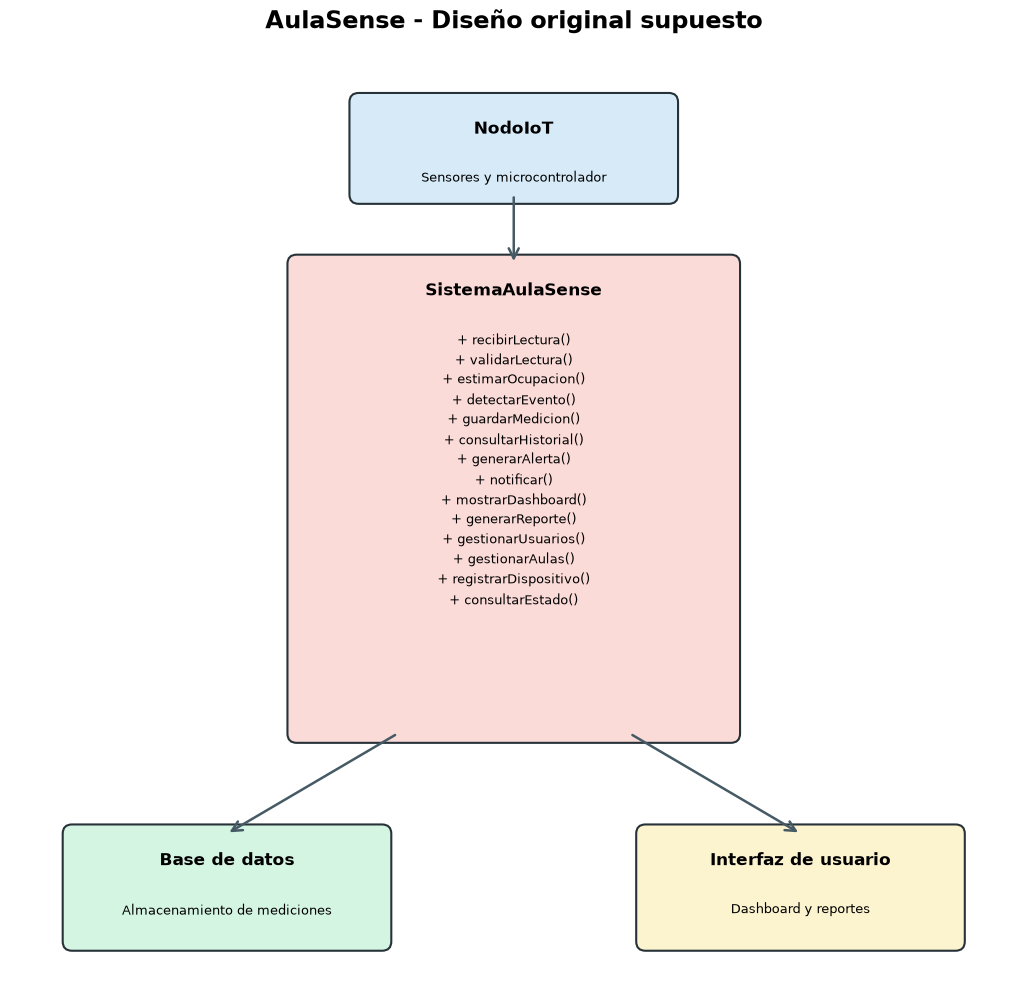

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 12))
ax.set_xlim(0, 13)
ax.set_ylim(0, 12)
ax.axis("off")

def caja(x, y, ancho, alto, titulo, contenido, color):
    rect = FancyBboxPatch(
        (x, y), ancho, alto,
        boxstyle="round,pad=0.12",
        linewidth=1.5,
        edgecolor="#263238",
        facecolor=color
    )
    ax.add_patch(rect)

    ax.text(
        x + ancho / 2, y + alto - 0.35,
        titulo, ha="center", va="center",
        fontsize=12, fontweight="bold"
    )

    ax.text(
        x + ancho / 2, y + alto - 0.85,
        contenido, ha="center", va="top",
        fontsize=9, linespacing=1.6
    )

def flecha(inicio, fin):
    ax.add_patch(
        FancyArrowPatch(
            inicio, fin,
            arrowstyle="->",
            mutation_scale=18,
            linewidth=1.8,
            color="#455A64"
        )
    )

caja(
    4.5, 10.2, 4, 1.2,
    "NodoIoT",
    "Sensores y microcontrolador",
    "#D6EAF8"
)

metodos = (
    "+ recibirLectura()\n"
    "+ validarLectura()\n"
    "+ estimarOcupacion()\n"
    "+ detectarEvento()\n"
    "+ guardarMedicion()\n"
    "+ consultarHistorial()\n"
    "+ generarAlerta()\n"
    "+ notificar()\n"
    "+ mostrarDashboard()\n"
    "+ generarReporte()\n"
    "+ gestionarUsuarios()\n"
    "+ gestionarAulas()\n"
    "+ registrarDispositivo()\n"
    "+ consultarEstado()"
)

caja(
    3.7, 3.2, 5.6, 6.1,
    "SistemaAulaSense",
    metodos,
    "#FADBD8"
)

caja(
    0.8, 0.5, 4, 1.4,
    "Base de datos",
    "Almacenamiento de mediciones",
    "#D5F5E3"
)

caja(
    8.2, 0.5, 4, 1.4,
    "Interfaz de usuario",
    "Dashboard y reportes",
    "#FCF3CF"
)

flecha((6.5, 10.2), (6.5, 9.3))
flecha((5, 3.2), (2.8, 1.9))
flecha((8, 3.2), (10.2, 1.9))

ax.set_title(
    "AulaSense - Diseño original supuesto",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.show()

## 5. Problemas identificados en el diseño original

### 5.1. Baja cohesión
La clase SistemaAulaSense realiza actividades muy diferentes,
como recibir datos, administrar usuarios, guardar mediciones
y generar reportes. Esto provoca que la clase tenga demasiadas
funciones que podrían estar separadas.

### 5.2. Alto acoplamiento
Las funciones del sistema dependen de una misma clase.
Por ejemplo, si se modifica la forma de almacenar las
mediciones, podrían verse afectadas otras operaciones
que utilizan esa información.

### 5.3. Dificultad de mantenimiento
Al concentrar tantas funciones en un solo lugar,
encontrar y corregir errores puede ser más complicado.
También aumenta el riesgo de afectar otras funciones
cuando se realiza una modificación.

### 5.4. Posible duplicación de código
Al manejar diferentes procesos dentro de la misma clase,
podrían repetirse validaciones o consultas en varios métodos.
Esto dificultaría mantener un comportamiento uniforme.

### 5.5. Dificultad para realizar pruebas
Es más complicado probar cada función de manera independiente
porque muchas operaciones están concentradas en una sola clase.

### 5.6. Poca facilidad para ampliar el sistema
Si en el futuro se agregan nuevos sensores, reportes o
funciones de monitoreo, la clase seguiría creciendo y
sería más difícil de organizar.

## 6. Conclusión del análisis original

El diseño original supuesto de AulaSense permite representar
las funciones principales del sistema, pero presenta problemas
de organización al concentrar demasiadas responsabilidades
en una sola clase.

Por esta razón, se propone dividir el sistema en clases
más pequeñas y especializadas, de manera que cada una
se encargue de una función específica.

A partir de este análisis, cada integrante del equipo
desarrollará una propuesta diferente para mejorar
la estructura del software.